# Linear Regression — Fast Food Protein Prediction

**University coursework | Artificial Intelligence, Faculty of Organizational Sciences, University of Belgrade**

This notebook is an edited version of my exercise/exam-preparation work. The goal is to predict the protein content of fast-food items using multiple linear regression.

The approach and code remain close to the version I worked through in class. Explanations have been translated into English and the notebook has been organized for readability. The example and dataset originate from the [course's public repository](https://github.com/vestackainteligencijafon/LR-Primer); this notebook does not claim the exercise idea or dataset as original research.


## 1. Import libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro


## 2. Load and inspect the data

The source file is `fastfood.csv`. We first check the columns, data types, and missing values.

In [9]:
df = pd.read_csv('fastfood.csv', na_values=['NA'])


In [10]:
df.head()


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,calcium
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37,20.0
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46,20.0
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70,50.0
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55,20.0
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46,20.0


In [11]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    str    
 1   item         515 non-null    str    
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    str    
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    str    
 13  calcium      305 non-null    float64
dtypes: float64(4), int64(6), str(4)
memory usage: 56.5 KB


In [12]:
print(df.isna().sum())


restaurant       0
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          1
calcium        210
dtype: int64


## 3. Prepare the dataset

Keep items with total fat at most 125, convert numeric columns and inspect missing values.

In [13]:
df_subset = df.loc[df['total_fat']<=125].copy()
print(f"Rows in df_subset:{len(df_subset)}")
print(f"Rows in original dataframe: {len(df)}")


Rows in df_subset:513
Rows in original dataframe: 515


In [14]:
nedostajuce = ['-', ' ', '']
print(df_subset.isin(['-',' ','']).sum())

df_subset.replace(nedostajuce,np.nan,inplace=True)

print(df_subset.isin(['-',' ','']).sum())


restaurant     3
item           0
calories       0
cal_fat        1
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        1
calcium        0
dtype: int64
restaurant     0
item           0
calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
calcium        0
dtype: int64


In [15]:
df_subset['protein'] = pd.to_numeric(df_subset['protein'], errors = 'coerce')
df_subset['cal_fat'] = pd.to_numeric(df_subset['cal_fat'], errors = 'coerce')

df_numeric = df_subset.select_dtypes(include=['number']).copy()

print(df_numeric.columns)
print(df_numeric.info())


Index(['calories', 'cal_fat', 'total_fat', 'sat_fat', 'trans_fat',
       'cholesterol', 'sodium', 'total_carb', 'fiber', 'sugar', 'protein',
       'calcium'],
      dtype='str')
<class 'pandas.DataFrame'>
Index: 513 entries, 0 to 514
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   calories     513 non-null    int64  
 1   cal_fat      512 non-null    float64
 2   total_fat    513 non-null    int64  
 3   sat_fat      513 non-null    float64
 4   trans_fat    513 non-null    float64
 5   cholesterol  513 non-null    int64  
 6   sodium       513 non-null    int64  
 7   total_carb   513 non-null    int64  
 8   fiber        501 non-null    float64
 9   sugar        513 non-null    int64  
 10  protein      511 non-null    float64
 11  calcium      304 non-null    float64
dtypes: float64(6), int64(6)
memory usage: 52.1 KB
None


### Handle missing values

Remove `calcium` because it contains many missing values. For selected other numeric columns, inspect their distributions and fill missing entries with the median.

In [16]:
print(df_numeric.isna().sum()) # Missing values per column


print((df_numeric.isna().mean() * 100).round(2))


df_numeric.drop(columns='calcium', inplace=True)


calories         0
cal_fat          1
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          2
calcium        209
dtype: int64
calories        0.00
cal_fat         0.19
total_fat       0.00
sat_fat         0.00
trans_fat       0.00
cholesterol     0.00
sodium          0.00
total_carb      0.00
fiber           2.34
sugar           0.00
protein         0.39
calcium        40.74
dtype: float64


In [17]:
cols_with_na = ['cal_fat','fiber','protein']

for col in cols_with_na:
    series = df_numeric[col].dropna()
    stat, p = shapiro(series)
    print(f"{col}: p = {p:.5f}")


for col in cols_with_na:
    median = df_numeric[col].median()
    df_numeric[col] = df_numeric[col].fillna(median)

print(df_numeric.isna().sum())


cal_fat: p = 0.00000
fiber: p = 0.00000
protein: p = 0.00000
calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
dtype: int64


## 4. Explore correlations

The correlation heatmap helps us choose candidate predictors for protein content.

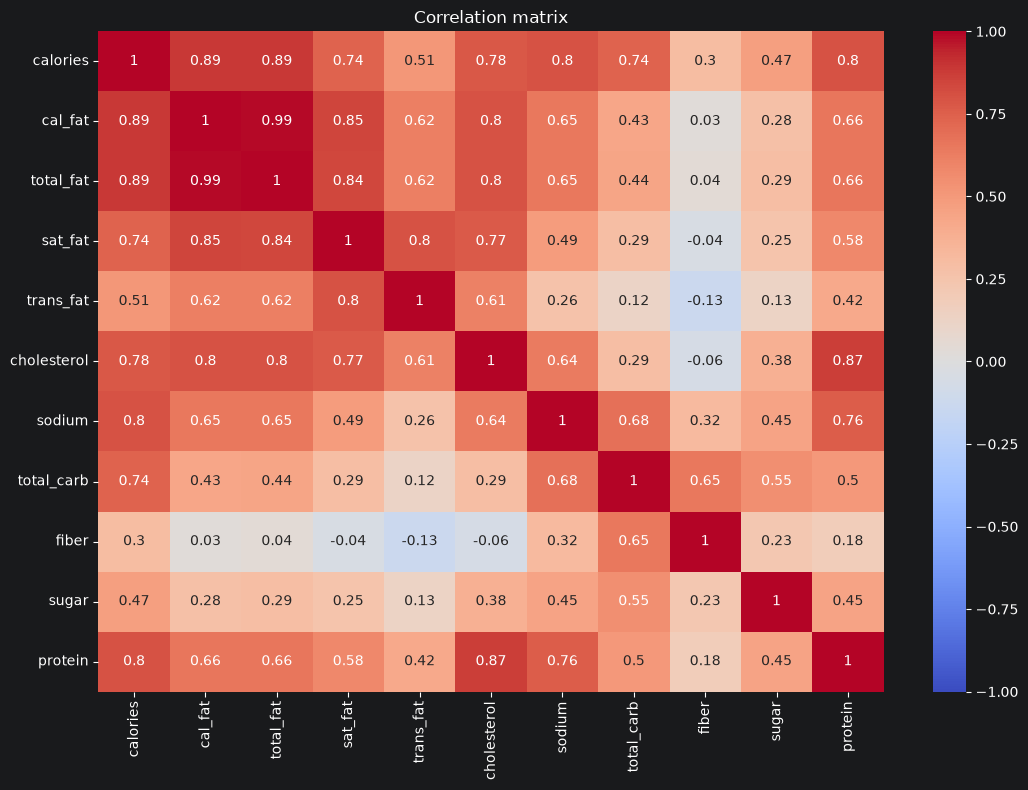

In [18]:
corr_matrix = df_numeric.corr(numeric_only=True).round(2)
plt.figure(figsize=(11, 8))
sb.heatmap(corr_matrix, annot=True,
           cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()


### Select variables

`protein` is the value we want to predict. We use `cholesterol`, `calories`, and `sodium` as predictors.

In [19]:
target = 'protein' # Target (y)


korelacija = ['cholesterol','calories','sodium']  # Predictors (X)


## 5. Split into training and test data

The cleaned numeric dataset is used here. **Small correction:** the original practice notebook split `df_subset`, despite cleaning `df_numeric` in the previous cells.

In [20]:
train_df,test_df = train_test_split(df_numeric, test_size=0.2,random_state=42)

print(f"Training rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")


Training rows: 410
Test rows: 103


## 6. Fit a multiple linear regression model

`statsmodels` provides coefficients and statistical measures for the fitted model.

In [21]:
lm1 = smf.ols(f'{target} ~'+'+'.join(korelacija),data = train_df).fit()
print(lm1.summary())


                            OLS Regression Results                            
Dep. Variable:                protein   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     661.6
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          7.05e-156
Time:                        17:58:48   Log-Likelihood:                -1323.4
No. Observations:                 410   AIC:                             2655.
Df Residuals:                     406   BIC:                             2671.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       2.9725      0.697      4.267      

### Reading the model summary

- **Intercept:** expected prediction when all predictors equal zero; this may have limited practical meaning.
- **Coefficients:** estimated change in protein for a one-unit increase in a predictor, holding the others constant.
- **R-squared:** share of training-data variation described by the model.
- **P-values and F-statistic:** statistical measures describing the fitted regression.
- **Condition number:** one possible warning sign of numerical instability or correlated predictors.

The exact values should be read from the output after running the notebook, rather than copied from an earlier run.

### Interpretation of the Regression Results

The multiple linear regression model uses cholesterol, calories, and sodium to predict the protein content of fast-food products.

**Intercept**

The intercept is approximately 2.97. It represents the predicted protein content when all independent variables are equal to zero.

**Regression Coefficients**

Holding the other predictors constant:

- A one-unit increase in cholesterol is associated with an increase of approximately 0.193 in predicted protein content.
- A one-unit increase in calories is associated with an increase of approximately 0.0073.
- A one-unit increase in sodium is associated with an increase of approximately 0.0056.

These coefficients describe statistical associations rather than causal relationships.

**R-squared**

The model explains approximately 83% of the variability in protein content within the training dataset.

**Statistical Significance**

The F-statistic and its very small p-value indicate that the regression model is statistically significant overall.

All three predictors also have p-values below 0.05, suggesting that they are statistically significant within this model.

**Condition Number**

The relatively high condition number suggests potential multicollinearity or numerical scaling issues, which should be investigated further.

## 7. Predict on the test data

Compare actual and predicted protein values.

In [22]:
y_true = test_df['protein'] # Actual protein values in the test set
X_test = test_df[['cholesterol','calories','sodium']]

y_pred = lm1.predict(X_test)


results = pd.DataFrame({'Actual': y_true.values, 'Predicted': y_pred.round(2)})
print(results.head(10))


     Actual  Predicted
306    19.0      19.06
498    13.0      17.52
441    12.0      15.80
154    49.0      47.67
500    14.0      16.82
132    11.0      17.91
206    13.0      14.37
509    23.0      25.47
327    20.0      21.96
249    37.0      27.57


## 8. Check regression diagnostics

We plot residuals, the Q–Q plot, scale-location, and influential observations.

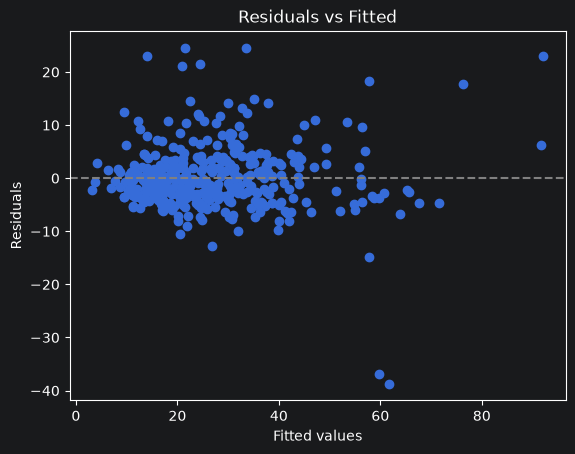

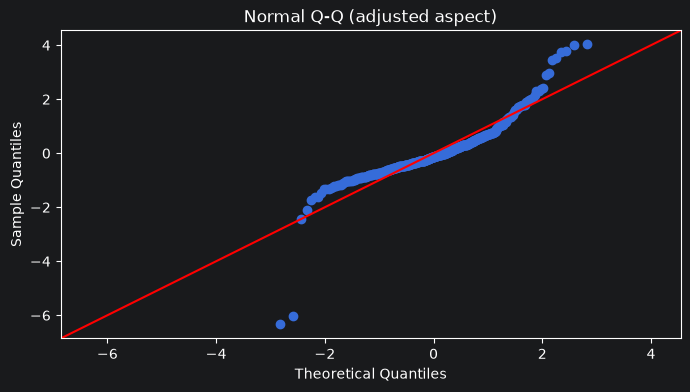

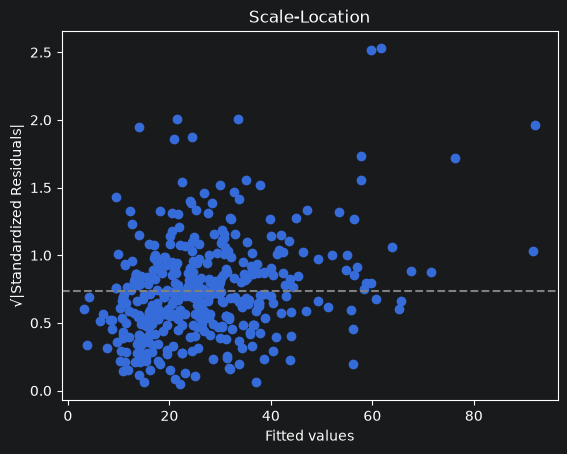

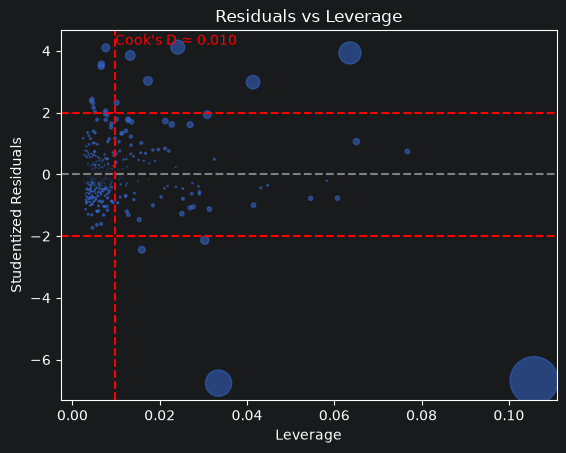

In [23]:
# Residuals vs Fitted
plt.scatter(lm1.fittedvalues, lm1.resid)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()
# Normal Q-Q plot
sm.qqplot(lm1.resid, line='45', fit=True)
plt.gcf().set_size_inches(8, 4)
plt.title("Normal Q-Q (adjusted aspect)")
plt.show()
# Scale-Location
influence = lm1.get_influence()
std_resid = influence.resid_studentized_internal
abs_sqrt_resid = np.sqrt(np.abs(std_resid))
plt.scatter(lm1.fittedvalues, abs_sqrt_resid)
plt.axhline(np.mean(abs_sqrt_resid), color='gray', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("√|Standardized Residuals|")
plt.title("Scale-Location")
plt.show()
# Residuals vs Leverage + Cook's D threshold
leverage = influence.hat_matrix_diag
stud_resid = influence.resid_studentized_external
cooks_d = influence.cooks_distance[0]
n = len(lm1.model.endog)
thresh = 4 / n

plt.scatter(leverage, stud_resid, s=1000 * cooks_d, alpha=0.5)
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(2, color='red', linestyle='--')
plt.axhline(-2, color='red', linestyle='--')
plt.axvline(thresh, color='red', linestyle='--')
plt.text(thresh, plt.ylim()[1]*0.9, f"Cook's D ≈ {thresh:.3f}", color='red')
plt.xlabel("Leverage")
plt.ylabel("Studentized Residuals")
plt.title("Residuals vs Leverage")
plt.show()


### Interpreting the diagnostic plots

- **Residuals vs fitted:** look for systematic patterns that the linear model may be missing.
- **Normal Q–Q:** deviations from the line can indicate non-normal residuals.
- **Scale-location:** look for a changing spread of residuals.
- **Residuals vs leverage:** investigate observations that may strongly influence the model.

These plots support a qualitative assessment; they do not, by themselves, prove that every model assumption holds.

### Interpretation of Diagnostic Plots

**1. Residuals vs Fitted Values**

This plot shows the differences between actual and predicted protein values.

Most residuals are distributed around zero, but some deviations suggest that the linear model may not fully capture all relationships in the dataset.

**2. Normal Q-Q Plot**

This plot is used to assess whether the residuals follow a normal distribution.

Several points deviate from the reference line, particularly toward the ends of the distribution.

Therefore, the assumption of normally distributed residuals does not appear to be fully satisfied.

**3. Scale-Location Plot**

This plot helps assess whether the variance of residuals remains constant across fitted values.

The spread of residuals is not completely uniform, suggesting possible heteroscedasticity.

**4. Residuals vs Leverage**

This plot helps identify observations that may have a strong influence on the regression model.

Several observations have relatively large residuals and leverage values.

These potentially influential observations could affect the stability of the estimated regression coefficients.

**Overall Assessment**

The diagnostic plots suggest that the model explains a substantial amount of variation in protein content, but some regression assumptions may not be fully satisfied.

## 9. Explore multicollinearity

Variance inflation factors (VIF) help us see whether predictors overlap in the information they provide.

In [24]:
X = sm.add_constant(train_df[korelacija])

vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])],index=X.columns)

print("Square-root VIF for all predictors:\n", np.sqrt(vif))


Square-root VIF for all predictors:
 const          1.000000
cholesterol    1.587883
calories       2.064371
sodium         1.666079
dtype: float64


### Try a model with two predictors

As an exercise, we also fit a model without `calories` and inspect VIF again. This is an exploratory alternative, not proof that the second model predicts better.

In [25]:
lm2 = smf.ols(f'{target}~ cholesterol + sodium', data = train_df).fit()


X = sm.add_constant(train_df[['cholesterol','sodium']])

vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)

print("Square-root VIF without calories:\n", np.sqrt(vif))


Square-root VIF without calories:
 const          1.00000
cholesterol    1.28145
sodium         1.28145
dtype: float64


### Comparison of the Two Regression Models

The initial regression model included three predictors: cholesterol, calories, and sodium.

After examining multicollinearity, calories was identified as the predictor with the highest square-root VIF value (approximately 2.06).

A second regression model was therefore created using only cholesterol and sodium.

Removing calories reduced multicollinearity between the remaining predictors.

The models were also compared using Mean Absolute Error (MAE) on the test dataset:

- Model 1 (three predictors): MAE = 3.58
- Model 2 (two predictors): MAE = 3.37

The second model achieved a slightly lower average prediction error.

This suggests that removing calories improved prediction performance for this particular train-test split while also reducing multicollinearity.

However, this result does not guarantee that the second model will always perform better on new data.

## 10. Limitations and next steps

This is a university practice example, not a production model. In the original exercise workflow, filling missing values and choosing predictors happen before the train/test split. In a larger real-world project these decisions should be learned from the training set to avoid information leakage. The simple exercise workflow has been retained here so that the notebook reflects the methods practiced in class.
